# Hierarchical Clustering - UPGMA

---
## Learning Objectives

1. Implement a distance-based phylogeny neighbor joining algorithm
1. Understanding of hierarchical clustering
1. Manipulation of arrays and lists in Python


---
## Imports
You will need to install a two new packages to properly render your phylogenetic trees. Using your preferred package manager, install both [`biopython`](https://biopython.org/) and `matplotlib` into your virtual environments.

For example:
```bash
$ micromamba create -n module06 -c bioconda -c conda-forge python numpy matplotlib biopython
```

In [ ]:
%pip install biopython matplotlib numpy

from typing import List, Tuple, Dict
from io import StringIO

import matplotlib.pyplot as plt
from Bio import Phylo
import numpy as np

---
## Background

Today we will implement a distance-based phylogenetic tree construction method using the Neighbor-Joining (NJ) algorithm and Smith-Waterman local alignment scores. Unlike UPGMA (Unweighted Pair Group Method using Arithmetic averages), NJ produces unrooted trees and does not assume a constant evolutionary rate across lineages, making it more biologically realistic for analyzing sequence relationships.

We will use HIV-1 reverse transcriptase sequences to construct our phylogenetic tree. The Smith-Waterman algorithm will be used to generate pairwise local alignment scores, which will then be converted into distances for tree construction. This approach is particularly suitable for HIV sequence analysis as it:
1. Handles sequence variations effectively through local alignment
2. Accounts for potential rate heterogeneity across different viral strains
3. Does not assume a molecular clock

The ultimate output will be an unrooted phylogenetic tree representing the evolutionary relationships between the HIV-1 sequences, visualized using the ete3 library. This method provides insights into viral diversity and evolutionary patterns while avoiding the assumptions of simpler hierarchical clustering approaches.

The key innovations of this implementation are:
- Use of Smith-Waterman for sensitive local alignment scoring
- Implementation of Neighbor-Joining for unrooted tree construction
- More biologically realistic evolutionary model

## Neighbor-Joining Algorithm

**Input**: Distance matrix $D$ for $n$ sequences

**Initialization**:
- Let $n$ be the number of sequences
- Assign each sequence $i$ to its own leaf node
- Initialize tree $T$ with leaf nodes

**Iteration**:
While $n > 2$:
1. Calculate Q-matrix where:
   $Q(i,j) = (n-2)d(i,j) - \sum_{k=1}^n d(i,k) - \sum_{k=1}^n d(j,k)$

2. Find pair $(i,j)$ with minimum $Q(i,j)$

3. Calculate branch lengths:
   $d_i = \frac{d(i,j) + (r_i - r_j)/(n-2)}{2}$
   $d_j = d(i,j) - d_i$
   where $r_i = \sum_{k=1}^n d(i,k)$

4. Create new node $k$
   - Add branches from $k$ to $i$ and $j$ with lengths $d_i$ and $d_j$

5. Update distances to remaining nodes $x$:
   $d(k,x) = \frac{d(i,x) + d(j,x) - d(i,j)}{2}$

6. Remove nodes $i$ and $j$
7. Add node $k$ to active nodes
8. $n = n - 1$

**Termination**:
When $n = 2$ with remaining nodes $i$ and $j$:
- Add final branch between $i$ and $j$ with length $d(i,j)$
- Return unrooted tree $T$

---
## Distance metrics for comparing sequences

### Smith-Waterman
This was previously implemented. Feel free to import if you know how...or Copy & Paste.



In [3]:
def read_fasta(filename: str) -> Dict[str, str]:
    """Reads sequences from FASTA file.

    Args:
        filename (str): Path to FASTA file containing HIV RT sequences

    Returns:
        Dict[str, str]: Dictionary mapping sequence IDs to sequences

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> len(seqs) > 0
        True

    Pseudocode:
    initialize empty dict seqs, current_id = None
        open file, for each line:
            strip whitespace, skip if empty
            if line starts with ">":
                current_id = last token of header - after ">"
                seqs[current_id] = ""
            else if current_id exists:
                append line to seqs[current_id]  (handles multi-line sequences)
        return seqs

    """
    seqs = {}
    current_id = None
    with open(filename) as file:
        for line in file:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                current_id = line[1:].split()[-1]   # after '>' is sequence ID
                seqs[current_id] = ""
            elif current_id is not None:
                seqs[current_id] += line           
    return seqs




In [4]:
def cal_score(matrix, seq1, seq2, i, j, match, mismatch, gap, best_score):
    '''Calculate score for position (i,j) in scoring matrix and update the best score.
    Args:
        matrix (numpy array): scoring matrix
        seq1 (str): sequence 1
        seq2 (str): sequence 2
        i (int): current row number
        j (int): current column number
        match, mismatch, gap (float): scoring parameters
        best (float): highest score seen so far

    Returns:
        score (float): score in position (i,j)
        best_score (float): updated highest score seen so far

    Pseudocode:
        if i == 0 or j == 0:
            return 0, best_score  (first row/column are boundary cells)
        diag_score = matrix[i-1][j-1] + (match if seq1[i-1] == seq2[j-1] else mismatch)
        up_score   = matrix[i-1][j] + gap
        left_score = matrix[i][j-1] + gap
        score = max(0, diag_score, up_score, left_score)  (0 = start new local alignment)
        best_score = max(best_score, score)
        return score, best_score

    '''
    
    if i == 0 or j == 0:
        return 0, best_score

    if seq1[i-1] == seq2[j-1]:
        diag_score = matrix[i-1][j-1] + match
    else:
        diag_score = matrix[i-1][j-1] + mismatch
    up_score = matrix[i-1][j] + gap
    left_score = matrix[i][j-1] + gap

    score = max(0, diag_score, up_score, left_score)
    best_score = max(best_score, score)

    return score, best_score


def smith_waterman(
    sequence1: str,
    sequence2: str,
    match_score: float = 2.0,
    mismatch_penalty: float = -1.0,
    gap_penalty: float = -1.0
) -> float:
    """Implements Smith-Waterman local alignment algorithm.

    Args:
        sequence1 (str): First HIV RT sequence
        sequence2 (str): Second HIV RT sequence
        match_score (float): Score for matching characters
        mismatch_penalty (float): Penalty for mismatched characters
        gap_penalty (float): Penalty for gaps

    Returns:
        float: Normalized similarity score between sequences

    Examples:
        >>> seq1 = "ACGT"
        >>> seq2 = "ACGT"
        >>> smith_waterman(seq1, seq2)
        1.0

    Pseudocode:
    Raw smith-waterman score is similarity, need to account for distance
    distance = 1 - similarity if similarity normalized to 0-1 range where 1.0 is a sequence aligned to itself
    adapt cal_score to remove tracking the move directions (not needed), but constantly track the highest score seen
    drop traceback since we only need the scores

        
    initialize (len1+1) x (len2+1) score matrix of 0s, best_score = 0
    for each cell (i, j):
        score_matrix[i][j], best_score = cal_score(...)
    self1 = match_score * len(sequence1)  (score of seq1 aligned to itself)
    self2 = match_score * len(sequence2)
    similarity = best_score / sqrt(self1 * self2)  (geometric mean normalizes to 0-1)
    return similarity  (1.0 = identical; distance conversion done in build_distance_matrix)
    """

    score_matrix = np.zeros((len(sequence1) + 1, len(sequence2) + 1))
    best_score = 0.0

    for i in range(len(sequence1) + 1):
        for j in range(len(sequence2) + 1):
            score_matrix[i][j], best_score = cal_score(score_matrix, sequence1, sequence2, i, j, match_score, mismatch_penalty, gap_penalty, best_score)

    # Get score for sequence 1 aligned with itself, sequence 2 aligned with itself, then take its geometric mean
    # Using best_score, see how close it came to best possible score as a number between 0 and 1
    # Useful for building distance matrix where we then do distance = 1 - similarity
    self1 = match_score * len(sequence1)
    self2 = match_score * len(sequence2)
    return float(best_score / np.sqrt(self1 * self2))



In [5]:
def build_distance_matrix(sequences: Dict[str, str]) -> Tuple[np.ndarray, List[str]]:
    """Builds DISTANCE (not similiarity) matrix using Smith-Waterman scores.

    Args:
        sequences (Dict[str, str]): Dictionary of HIV RT sequences

    Returns:
        Tuple[np.ndarray, List[str]]: Distance matrix and list of sequence IDs

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> mat[0:3, 0:3]  # Show 3x3 slice of distance matrix
        array([[0.000, 0.004, 0.012],
              [0.004, 0.000, 0.012],
              [0.012, 0.012, 0.000]])
        >>> len(ids)  # Number of sequences
        19

    Pseudocode:
    Loop over every pair of sequences in dictionary, put sequence IDs in a list
    Initialize nxn matrix of 0s
    run smith_waterman on each pair i,j with i<j, convert with distance = 1- similarity
    Place result into the cell [i,j] of nxn numpy array - Only need to compute the upper triangle i<j , & since its symmetric write into both [i,j] and [j,i], diagonal is 0
    return matrix and ID list as tuple

    seq_ids = list of sequence IDs  (fixes row/column order)
        n = number of sequences
        initialize n x n matrix of 0s  (diagonal stays 0)
        for each pair i < j:
            similarity = smith_waterman(seq_i, seq_j)
            distance = 1 - similarity
            matrix[i, j] = matrix[j, i] = distance  (symmetric)
        return matrix, seq_ids

    """
    seq_ids = list(sequences.keys())
    n = len(seq_ids)
    distance_matrix = np.zeros((n, n))

    # Run on upper triangle only i<j, skip diagonal
    for i in range(n):
        for j in range(i + 1, n):          
            similarity = smith_waterman(sequences[seq_ids[i]], sequences[seq_ids[j]])
            distance = 1.0 - similarity
            distance_matrix[i, j] = distance
            distance_matrix[j, i] = distance # Mirror upper triangle results into lower triangle

    return distance_matrix, seq_ids


In [6]:
def neighbor_joining(
    distance_matrix: np.ndarray,
    labels: List[str]
) -> str:
    """Implements Neighbor-Joining algorithm for phylogenetic tree construction.

    Args:
        distance_matrix (np.ndarray): Distance matrix from Smith-Waterman scores
        labels (List[str]): Sequence identifiers

    Returns:
        str: Newick format tree string

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> tree = neighbor_joining(mat, ids)
        >>> tree.startswith("((DM1:0.002,DM2:0.002)")  # Start of Newick string
        True
        >>> tree.count(",")  # Number of separators in tree
        18

    Pseudocode:
    copy distance matrix, nodes = copy of labels, n = number of nodes
        if n == 0: return ";"    if n == 1: return "label;"
        while n > 2:
            1. row_totals TD(i) = sum of row i
            2. Q(i,j) = (n-2) * D(i,j) - TD(i) - TD(j)
               set diagonal of Q to infinity  (a node can't join itself)
            3. (i, j) = position of minimum Q  (i < j since Q is symmetric)
            4. branch lengths:
               di = D(i,j)/2 + (TD(i) - TD(j)) / (2(n-2))
               dj = D(i,j) - di
               clamp negative branch lengths to 0
            5. new node label = "(node_i:di,node_j:dj)"  (Newick string builds itself)
            6. distances to new node: D(u,k) = (D(i,k) + D(j,k) - D(i,j)) / 2
            7. overwrite row/column i with new distances, set D(u,u) = 0
               delete row and column j
               nodes[i] = new label, delete nodes[j]
            8. n = n - 1
        when 2 nodes remain:
            split final distance d in half between them
            return "(node_0:d/2,node_1:d/2);"

    """

    # Create a copy of the original matrix

    distance_matrix = np.array(distance_matrix, dtype=float).copy()

    # Newick strings comment here

    nodes = list(labels)
    n = len(nodes)

    # Edge cases check
    if n == 0:
        return ";"
    if n == 1:
        return f"{nodes[0]};"

    # ITERATION LOOP:
    # Join until 2 are left
    while n > 2:

        # Calculate Total Distance (TD) of each row
        row_totals = distance_matrix.sum(axis=1)

        # 1. Calculate the Q-matrix where
        # Q(i,j) = (n-2) * d(i,j) - (sum_{k=1}^n d(i,k)) - (sum_{k=1}^n d(j,k))
        # row_totals[:, None] = row of Q matrix
        # row_totals[None, :] = column of Q matrix
        #Numpy broadcasting?

        Q = (n-2) * distance_matrix - row_totals[:, None] - row_totals[None, :]

        # The diagonal of the matrix is all 0, meaning one HIV variant cannot be joined with itself. Using Numpy, give a variable where it won't be selected.
        np.fill_diagonal(Q, np.inf)

        # 2. Find pair (i, j) with minimum Q(i, j)
        # argmin = locates lowest number on the matrix, outputs the flat_ index
        # unravel_index = creates coordinates for the argmin output
        i,j = np.unravel_index(Q.argmin(), Q.shape)

        # Distance between the two nodes being joined
        dij = distance_matrix[i, j]

        # 3. Calculate the branch lengths:
        #   d_i = \frac{d(i,j) + (r_i - r_j)/(n-2)}{2},
        #   d_j = d(i,j) - d_i$
        #   where r_i = \sum_{k=1}^n d(i,k)
        di = 0.5 * dij + (row_totals[i] - row_totals[j]) / (2 * (n-2))
        dj = dij - di

        # NJ can produce negative branch lengths. Quick fix to make sure all the values stay positive.
        di, dj = max(di, 0), max(dj, 0)

        # 4. Create new node k (fprmatted as a Newick string)
        #   Add branches from k to i and j with lengths d_i and d_j
        new_node_k = f"({nodes[i]}:{di:.3f},{nodes[j]}:{dj:.3f})"

        # 5. Update distances to remaining nodes x:
        #   d(k,x) = \frac{d(i,x) + d(j,x) - d(i,j)}{2}
        d_new = (distance_matrix[i] + distance_matrix[j] - dij) / 2

        # 6. Remove nodes i and j
        # 7. Add node k to active nodes
        distance_matrix[i, :] = d_new  # new row for k
        distance_matrix[:, i] = d_new  # new column for k
        distance_matrix[i, i] = 0      # distance from k to itself (diagonal)

        # Remove row j and column j from the matrix
        distance_matrix = np.delete(distance_matrix, j, axis = 0)
        distance_matrix = np.delete(distance_matrix, j, axis = 1)

        # Update the node list
        nodes[i] = new_node_k
        del nodes[j]

        # 8. n = n - 1
        n -= 1

    # TERMINATION
    # When n = 2 with remaining nodes i and j:
        # add final branch between i and j with length d(i,j)
        # return unrooted tree 
    d = distance_matrix[0, 1]
    return f"({nodes[0]}:{d / 2:.3f},{nodes[1]}:{d / 2:.3f});"

In [7]:
def plot_tree(newick_tree: str) -> None:
    """Plots a phylogenetic tree from a Newick string using Biopython and Matplotlib.

    The tree is rendered in a rectangular layout with smaller leaf labels and
    added margins to reduce overlap between labels and branches.

    Args:
        newick_tree (str): Tree in Newick format

    Returns:
        None: Displays the plotted tree
    """
    handle = StringIO(newick_tree)
    tree = Phylo.read(handle, "newick")

    fig, ax = plt.subplots(figsize=(8, 10))

    Phylo.draw(
        tree,
        axes=ax,
        do_show=False,
        label_func=lambda clade: clade.name if clade.is_terminal() else None,
    )
    for text in ax.texts:
        text.set_fontsize(6)              # shrink labels
    ax.margins(x=0.1, y=0.05)             # extra padding around tree

    plt.tight_layout()
    plt.show()


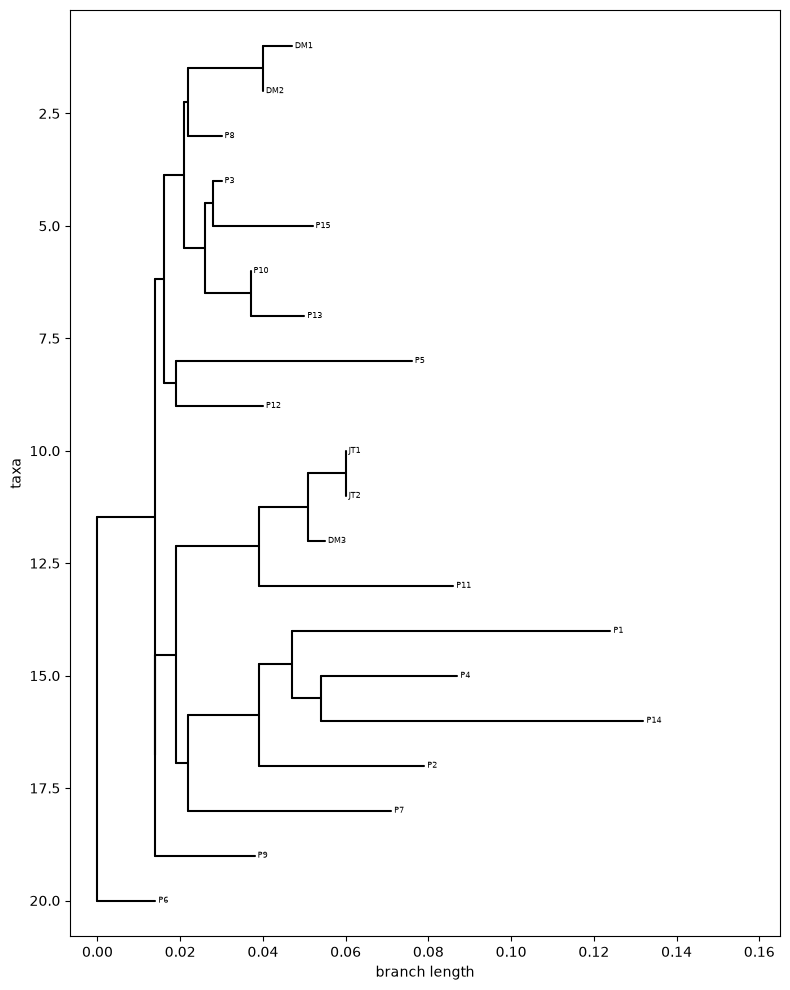

In [9]:
if __name__ == "__main__":
    # Read HIV RT sequences
    sequences = read_fasta("lafayette_SARS_RT.fasta")
    
    # Build distance matrix using Smith-Waterman
    dist_matrix, seq_ids = build_distance_matrix(sequences)
    
    # Generate unrooted tree using Neighbor-Joining
    tree = neighbor_joining(dist_matrix, seq_ids)
    
    # Plot tree
    plot_tree(tree)